# Imports

In [21]:
# %pip install tensorflow
# %pip install --upgrade tensorflow keras
# %pip install keras_tuner
# %pip install huggingface_hub
# %pip install datasets
# %pip install ipywidgets

In [1]:
import os
import glob
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from PIL import Image
import keras
from keras import layers
import keras_tuner as kt
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

RANDOM_STATE = 1234

In [2]:
def load_npz_dataframe(
    data_dir="data/", 
    metadata_path="vial_metadata.json", 
    train_size=0.7, 
    val_size=0.20, 
    test_size=0.10
):    
    """
    Scans the data directory, reads the JSON registry, dynamically maps 
    encountered species to integer labels, and handles small-batch splitting.
    """
    assert abs((train_size + val_size + test_size) - 1.0) < 1e-5, "Split proportions must sum to 1.0"
    with open(metadata_path, 'r', encoding='utf-8') as f:
        vial_registry = json.load(f)
        
    files = glob.glob(os.path.join(data_dir, "*.npz"))
    data = []
    for f in files:
        file_name = os.path.basename(f)
        parts = file_name.split('_')
        vial_number, sample_letter, capture_number = parts[0], parts[1], parts[2].replace(".npz", "")
        if len(parts) < 3:
            print(f"Warning: Unexpected filename format for {file_name}. Skipping.")
            continue
        if vial_number in vial_registry:
            species_id = vial_registry[vial_number].get("Species ID")
            data.append({
                "filepath": f, 
                "vial": vial_number,
                "sample": sample_letter,
                "capture": capture_number,
                "species": species_id
            })
                
    df = pd.DataFrame(data)        
    unique_species = df['species'].unique()
    species_to_label = {species: i for i, species in enumerate(unique_species)}
    df['label'] = df['species'].map(species_to_label)
    
    min_class_count = df['label'].value_counts().min()
    use_stratify = df['label'] if min_class_count >= 4 else None
    if use_stratify is None:
        print("Notice: Class counts too low for stratification. Using random split.")
    
    # Split 1: Separate Train from (Val + Test)
    temp_size = val_size + test_size
    train_df, temp_df = train_test_split(
        df, test_size=temp_size, stratify=use_stratify, random_state=RANDOM_STATE
    )

    # Split 2: Separate Val from Test
    temp_min = temp_df['label'].value_counts().min()
    use_stratify_temp = temp_df['label'] if (use_stratify is not None and temp_min >= 2) else None
    
    # Calculate what fraction of the temp_df needs to go to the test set
    test_fraction_of_temp = test_size / temp_size
    val_df, test_df = train_test_split(
        temp_df, test_size=test_fraction_of_temp, stratify=use_stratify_temp, random_state=RANDOM_STATE
    )
    
    print(f"Loaded {len(train_df)} training, {len(val_df)} validation, and {len(test_df)} testing samples.")
    return train_df, val_df, test_df, len(unique_species)
train_df, val_df, test_df, NUM_CLASSES = load_npz_dataframe()

Loaded 6 training, 2 validation, and 2 testing samples.


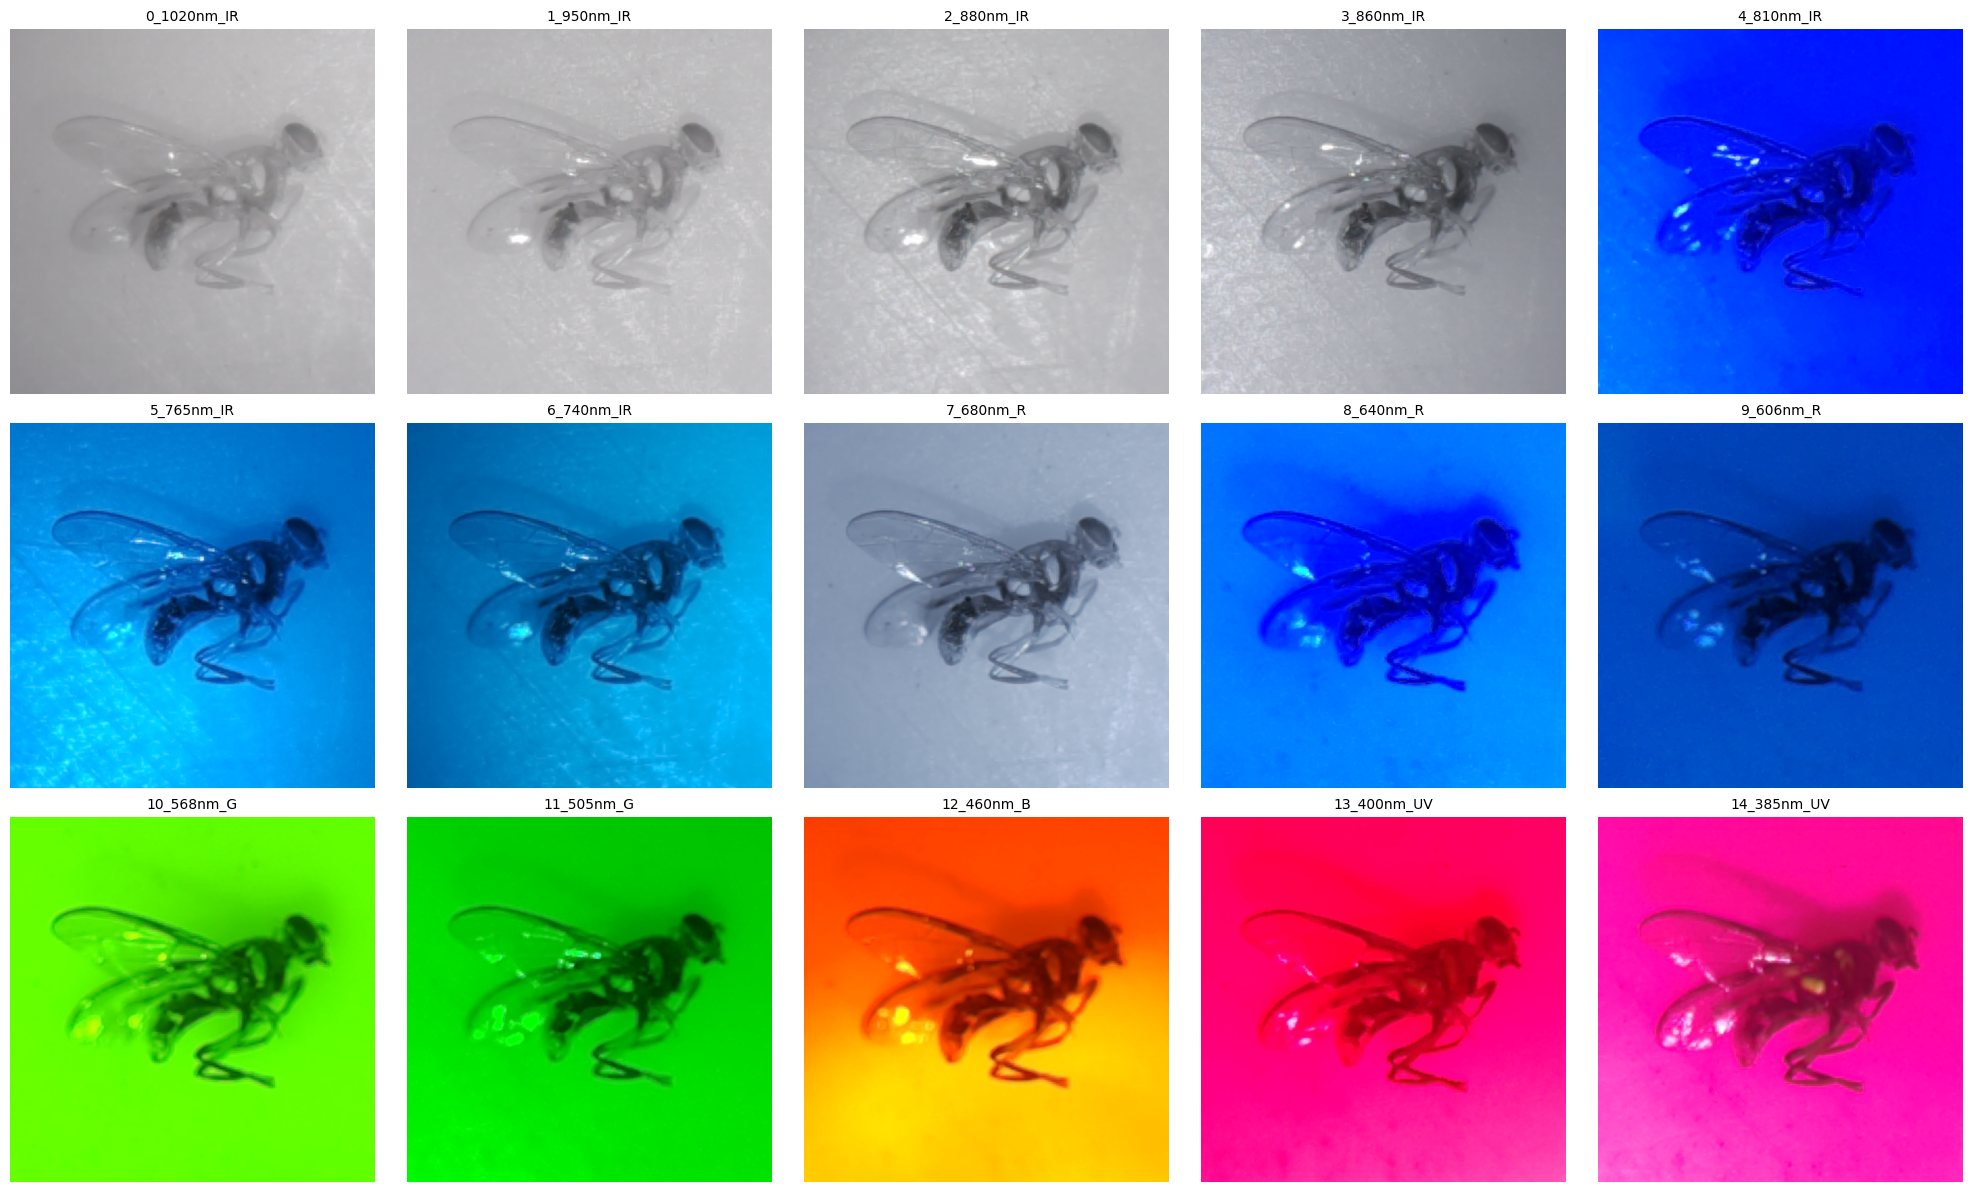

In [ ]:
def static_cube_grid(filepath):
    with np.load(filepath, allow_pickle=True) as data:
        img_cube = data['data']
        bands = data['bands']
        
    fig, axes = plt.subplots(3, 5, figsize=(20, 12))
    axes = axes.flatten()
    
    for i in range(15):
        axes[i].imshow(img_cube[:, :, :, i])
        axes[i].set_title(bands[i], fontsize=10)
        axes[i].axis('off')
        
    plt.tight_layout()
    plt.show()

static_cube_grid(train_df.iloc[0]['filepath'])

In [18]:
# 2. Build the multispectral tf.data pipeline
def create_multispectral_tf_dataset(df, num_spectral_bands=15, batch_size=32, img_size=(224, 224), is_training=False):
    paths = df['filepath'].values
    labels = df['label'].values
    total_channels = 3 * num_spectral_bands
    
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    
    def load_npz_image(path, label):
        def _load_numpy(file_path):
            file_path = file_path.decode('utf-8')
            with np.load(file_path, allow_pickle=True) as data:
                img = data['data'] 
            h, w, c, b = img.shape
            img_reshaped = img.reshape(h, w, c * b)
            return img_reshaped.astype(np.float32) / 255.0

        img = tf.numpy_function(_load_numpy, [path], tf.float32)
        img.set_shape((700, 700, total_channels))
        img = tf.image.resize(img, img_size)
        return img, label
        
    ds = ds.map(load_npz_image, num_parallel_calls=tf.data.AUTOTUNE)
    if is_training:
        ds = ds.shuffle(buffer_size=len(df))
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_dataset = create_multispectral_tf_dataset(train_df, is_training=True)
val_dataset = create_multispectral_tf_dataset(val_df)
test_dataset = create_multispectral_tf_dataset(test_df)


In [ ]:
# 3. Keras Tuner Model Builder
def model_builder(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(224, 224, 45))) 

    # Conv Layer 1
    model.add(layers.Conv2D(
        filters=hp.Int('filters1', 32, 128, step=16),
        kernel_size=hp.Choice('kernel1', [3, 5]),
        activation='relu',
        padding='same'
    ))
    if hp.Choice("layer_1_pool_type", ["max", "avg"]) == "max":
        model.add(layers.MaxPooling2D())
    else:
        model.add(layers.AveragePooling2D(pool_size=(2, 2)))
    
    if hp.Boolean('use_dropout1'):
        model.add(layers.Dropout(hp.Float('dropout1', 0.1, 0.5)))

    # Conv Layer 2
    model.add(layers.Conv2D(
        filters=hp.Int('filters2', 32, 128, step=16),
        kernel_size=hp.Choice('kernel2', [3, 5]),
        activation='relu',
        padding='same'
    ))
    if hp.Choice("layer_2_pool_type", ["max", "avg"]) == "max":
        model.add(layers.MaxPooling2D())
    else:
        model.add(layers.AveragePooling2D(pool_size=(2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(
        units=hp.Int('dense_units', 64, 256, step=32),
        activation='relu'
    ))

    if hp.Boolean('use_dropout2'):
        model.add(layers.Dropout(hp.Float('dropout2', 0.1, 0.5)))

    # Dynamically scale output nodes based on discovered species
    model.add(layers.Dense(NUM_CLASSES, activation='softmax'))

    learning_rate = hp.Float('lr', 1e-5, 1e-2, sampling='log')
    optimizer_choice = hp.Choice('optimizer', ['adam', 'rmsprop'])
    opt = keras.optimizers.Adam(learning_rate) if optimizer_choice == 'adam' else keras.optimizers.RMSprop(learning_rate)

    model.compile(
        optimizer=opt,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model